# Random Forest: many trees vote on grid stability

**Goal.** Reduce the variance of a single tree by averaging many different trees.

**The model.** Each tree is trained on a random bootstrap sample and, at each split, sees a random subset of features.
Samples left out of a tree's bootstrap are the **out-of-bag (OOB)** samples, and give a free estimate of test accuracy.

**The dataset.** *Electrical Grid Stability Simulated Data* (UCI): 10,000 simulations of a 4-node grid.
Inputs are reaction times (`tau`), power balances (`p`) and price elasticities (`g`). The target says if the grid is stable.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "grid"
archive = download("https://archive.ics.uci.edu/static/public/471/electrical+grid+stability+simulated+data.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\grid\dataset.zip
Files: ['dataset.zip', 'Data_for_UCI_named.csv']


In [4]:
import pandas as pd

df = pd.read_csv(DATA_DIR / "Data_for_UCI_named.csv")

# IMPORTANT: "stab" is the numeric value that the label "stabf" is computed from.
# Keeping it would leak the answer into the inputs, so it must be removed.
X = df.drop(columns=["stab", "stabf"])
y = (df["stabf"] == "unstable").astype(int)   # 1 = unstable
print("Shape:", X.shape, "| Unstable share:", round(y.mean(), 3))

Shape: (10000, 12) | Unstable share: 0.638


In [5]:
from sklearn.model_selection import train_test_split

# The same split as the decision tree notebook, so that the two are comparable.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

## 2. How many trees are enough?
`warm_start=True` keeps existing trees and adds new ones, so the whole curve costs about one training run.

In [6]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(warm_start=True, oob_score=True, n_jobs=-1, random_state=SEED)
tree_counts = list(range(25, 401, 25))
oob_error = []
for n in tree_counts:
    forest.set_params(n_estimators=n)
    forest.fit(X_train, y_train)
    oob_error.append(1 - forest.oob_score_)
print("OOB error with 25 trees: ", round(oob_error[0], 4))
print("OOB error with 400 trees:", round(oob_error[-1], 4))

OOB error with 25 trees:  0.1135
OOB error with 400 trees: 0.082


## 3. Test the forest and compare with one tree

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.tree import DecisionTreeClassifier

y_pred = forest.predict(X_test)
accuracy, f1 = accuracy_score(y_test, y_pred), f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
tree_accuracy = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train).score(X_test, y_test)
print(f"Forest: {accuracy:.4f} | Single unlimited tree: {tree_accuracy:.4f}")

Forest: 0.9265 | Single unlimited tree: 0.8495


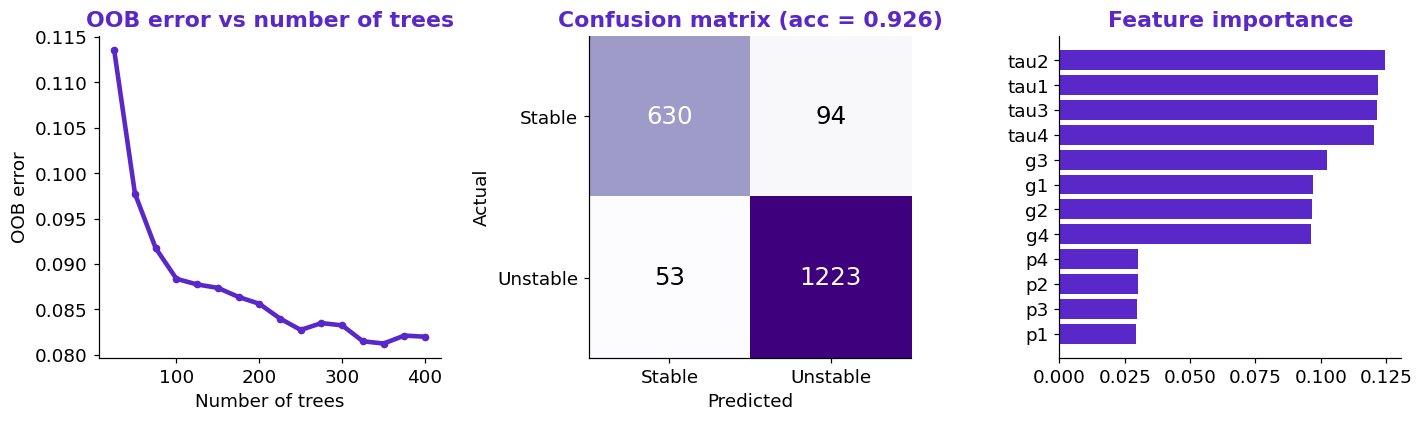

In [8]:
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(tree_counts, oob_error, color=PURPLE, lw=3, marker="o", ms=4)
ax[0].set(title="OOB error vs number of trees", xlabel="Number of trees", ylabel="OOB error")

ax[1].imshow(cm, cmap="Purples")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, v, ha="center", va="center", fontsize=16, color="white" if v > cm.max() / 2 else "black")
ax[1].set(title=f"Confusion matrix (acc = {accuracy:.3f})", xticks=[0, 1], yticks=[0, 1],
          xticklabels=["Stable", "Unstable"], yticklabels=["Stable", "Unstable"], xlabel="Predicted", ylabel="Actual")

ax[2].barh(importance.index, importance.values, color=PURPLE)
ax[2].set(title="Feature importance")
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "04_random_forest.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Random Forest",
    "dataset": "Electrical Grid Stability (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"Accuracy": round(accuracy, 4), "F1": round(f1, 4), "OOB accuracy": round(1 - oob_error[-1], 4), "Single tree acc": round(tree_accuracy, 4)},
}
(results_dir / "04_random_forest.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Random Forest",
  "dataset": "Electrical Grid Stability (UCI)",
  "n_samples": 10000,
  "metrics": {
    "Accuracy": 0.9265,
    "F1": 0.9433,
    "OOB accuracy": 0.918,
    "Single tree acc": 0.8495
  }
}


## What to remember
- Adding trees does not cause overfitting; the error simply levels off.
- A forest is more accurate than one tree, but harder to explain.